# HW 1 Part E: Sensitivity analysis of the SEIR model

**Question.** How do the transmission rate $\beta$ and the recovery rate $\gamma$ change (1) the **peak number of
simultaneously infectious people** and (2) the **total number of new infections in the first 365 days**?

**Model.** The SEIR model with births and deaths from Part D (`seir_rhs` in `epimodels.py`, unchanged), with the
Part D initial conditions $S(0)=1980,\ E(0)=15,\ I(0)=5,\ R(0)=0$ and fixed $N=2000$, $\sigma=0.25$, $\mu=0.005$ per day.

**Grid (E(i)).** $\beta\in[0.05,\,0.25]\times10^{-3}$ per person per day and $\gamma\in[0.05,\,0.25]$ per day, **9 × 9 = 81 runs**
(step 0.025 in both). The step was chosen so that the Part D values $\beta=0.125\times10^{-3}$, $\gamma=0.1$ are **grid
points**: the heatmaps contain the Part D epidemic, and it can be checked against Part D directly. A finer
81 × 81 grid (same solver) is used for the contour plots and the derivatives.

**Solver.** The same hand-written RK4 (`rk4_step`, `simulate`), $h=0.1$ day, 365 days. Results are labelled
**[numerical]** (from the RK4 trajectories) or **[analytical]** (derived from the equations provided).

**Reproduction number** (Part D(iv)):
$$R_0=\frac{\beta N\sigma}{(\sigma+\mu)(\gamma+\mu)}\quad\Longrightarrow\quad
R_0=1\ \text{ on the line }\ \beta^*(\gamma)=\frac{(\sigma+\mu)(\gamma+\mu)}{N\sigma}.$$

In [ ]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from scipy.integrate import solve_ivp       # used to verify the RK4
from epimodels import seir_rhs, simulate, rk4_step

os.makedirs("figures", exist_ok=True)
C_BETA, C_GAMMA = "tab:blue", "tab:orange"        # one colour per parameter, used in every figure
HALO = [pe.withStroke(linewidth=4, foreground="white")]   

## Parameters

In [ ]:
N      = 2000                                   # population size (subjects/people)
y0     = np.array([1980.0, 15.0, 5.0, 0.0])     # S(0), E(0), I(0), R(0) (people) -- as in Part D
sigma  = 0.25                                   # latent -> infectious rate (per day), fixed
mu     = 0.005                                  # birth = death rate (per day), fixed
T      = 365                                    # simulated days
h      = 0.1                                    # RK4 step size (days)

beta0, gamma0 = 0.125e-3, 0.1                   # Part D values = baseline of the sensitivity analysis
n_grid = 9                                      # values per parameter (assignment: at least 5)
betas  = np.linspace(0.05e-3, 0.25e-3, n_grid)  # transmission rate (per person per day)
gammas = np.linspace(0.05, 0.25, n_grid)        # recovery rate (per day)

base = {"beta": beta0, "gamma": gamma0, "sigma": sigma, "mu": mu, "N": N}
i0, j0 = int(np.argmin(abs(betas - beta0))), int(np.argmin(abs(gammas - gamma0)))   # baseline grid indices
print("beta values (x1e-3):", np.round(betas * 1e3, 4))
print("gamma values       :", np.round(gammas, 4))
print(f"Part D baseline on the grid: beta[{i0}] = {betas[i0]:.4g}, gamma[{j0}] = {gammas[j0]:.4g} ->",
      np.isclose(betas[i0], beta0) and np.isclose(gammas[j0], gamma0))

beta values (x1e-3): [0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25 ]
gamma values       : [0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25 ]
Part D baseline on the grid: beta[3] = 0.000125, gamma[2] = 0.1 -> True


### Helper functions

* `R0_seir`, `beta_on_R0_1`: the analytical $R_0$ and the $R_0=1$ line.
* `seir_rhs_counted`: the unchanged `seir_rhs` plus a **fifth variable** $C(t)$ with $dC/dt=\beta S I$, the number of new
  infections per day (the S → E flow). $C$ does not feed back into $S,E,I,R$, so the epidemic is identical to Part D,
  and RK4 integrates $C$ with the same 4th-order accuracy: $C(365)=\int_0^{365}\beta S I\,dt$.
* `run_one`: one simulation with `simulate`; returns the peak of $I$, its day, and $C(365)$.

**Why not $N-S(365)$?** With births, $S$ is refilled by $\mu N=10$ newborns per day and also loses people to death,
so $N-S(365)$ is not a count of infections (shown numerically below).

In [3]:
def R0_seir(beta, gamma):
    # [analytical] basic reproduction number of the SEIR model with births/deaths (Part D(iv))
    return beta * N * sigma / ((sigma + mu) * (gamma + mu))

def beta_on_R0_1(gamma):
    # [analytical] the beta at which R0 = 1, for a given gamma (R0 = 1 solved for beta)
    return (sigma + mu) * (gamma + mu) / (N * sigma)

def seir_rhs_counted(t, y, p):
    # y = [S, E, I, R, C]; C counts new infections: dC/dt = beta*S*I. Works for one run (y shape (5,))
    # or many runs at once (y shape (5, M), with p['beta'], p['gamma'] arrays of length M).
    S, E, I, R, C = y
    return np.concatenate([seir_rhs(t, y[:4], p), [p["beta"] * S * I]])

def run_one(beta, gamma, h=h, t_end=T):
    p = {**base, "beta": beta, "gamma": gamma}
    t, Y = simulate(seir_rhs_counted, np.append(y0, 0.0), t_end, h, p)
    k = int(np.argmax(Y[:, 2]))                       # grid point of the highest I (first one if tied)
    return {"t": t, "Y": Y, "peak_I": Y[k, 2], "t_peak": t[k], "cum_inf": Y[-1, 4]}

---
## E(i) The 9 × 9 parameter grid

A plain double loop: one call of `simulate` per $(\beta,\gamma)$ pair. Rows of every result array are $\beta$,
columns are $\gamma$. Arrays start as NaN, so a missed combination would be detected.

In [4]:
shape   = (n_grid, n_grid)
peak_I  = np.full(shape, np.nan)        # max_t I(t) on [0, 365]          (people)
t_peak  = np.full(shape, np.nan)        # day of that maximum              (days)
cum_inf = np.full(shape, np.nan)        # C(365) = integral of beta*S*I    (infections)
min_val = np.full(shape, np.nan)        # smallest S, E, I or R value in the run
drift   = np.full(shape, np.nan)        # max |S+E+I+R - N| in the run
finite  = np.zeros(shape, dtype=bool)   # every value of the run finite?
I_traj  = np.full(shape + (int(round(T / h)) + 1,), np.nan)   # I(t) of every run, for plotting

t_start = time.perf_counter()
for i, b in enumerate(betas):
    for j, g in enumerate(gammas):
        r = run_one(b, g)
        peak_I[i, j], t_peak[i, j], cum_inf[i, j] = r["peak_I"], r["t_peak"], r["cum_inf"]
        SEIR = r["Y"][:, :4]
        min_val[i, j] = SEIR.min()
        drift[i, j]   = np.abs(SEIR.sum(axis=1) - N).max()
        finite[i, j]  = np.isfinite(r["Y"]).all()
        I_traj[i, j]  = r["Y"][:, 2]
t = r["t"]
print(f"{n_grid * n_grid} simulations of {T} days (RK4, h = {h}) in {time.perf_counter() - t_start:.1f} s")

R0_grid = R0_seir(betas[:, None], gammas[None, :])

def print_grid(A, title, fmt="{:7.1f}"):
    print(f"\n{title}\n beta(1e-3) \\ gamma " + "".join(f"{g:7.3f}" for g in gammas))
    for i, b in enumerate(betas):
        print(f"   {b * 1e3:6.3f}         " + "".join(fmt.format(v) for v in A[i]))

print_grid(R0_grid, "[analytical] R0", "{:7.2f}")
print_grid(peak_I,  "[numerical] peak number of infectious people, max I(t) (people)")
print_grid(cum_inf, "[numerical] new infections in the first 365 days, C(365) (infections)")
print_grid(t_peak,  "[numerical] day of the peak (days)")

81 simulations of 365 days (RK4, h = 0.1) in 10.9 s

[analytical] R0
 beta(1e-3) \ gamma   0.050  0.075  0.100  0.125  0.150  0.175  0.200  0.225  0.250
    0.050            1.78   1.23   0.93   0.75   0.63   0.54   0.48   0.43   0.38
    0.075            2.67   1.84   1.40   1.13   0.95   0.82   0.72   0.64   0.58
    0.100            3.57   2.45   1.87   1.51   1.27   1.09   0.96   0.85   0.77
    0.125            4.46   3.06   2.33   1.89   1.58   1.36   1.20   1.07   0.96
    0.150            5.35   3.68   2.80   2.26   1.90   1.63   1.43   1.28   1.15
    0.175            6.24   4.29   3.27   2.64   2.21   1.91   1.67   1.49   1.35
    0.200            7.13   4.90   3.73   3.02   2.53   2.18   1.91   1.71   1.54
    0.225            8.02   5.51   4.20   3.39   2.85   2.45   2.15   1.92   1.73
    0.250            8.91   6.13   4.67   3.77   3.16   2.72   2.39   2.13   1.92

[numerical] peak number of infectious people, max I(t) (people)
 beta(1e-3) \ gamma   0.050  0.075  0.100  0

### Verification 1: completeness, finiteness, nonnegativity, conservation, Part D reproduced

In [5]:
# 1. Every combination evaluated
assert np.isfinite(peak_I).all() and np.isfinite(cum_inf).all() and np.isfinite(t_peak).all()
print(f"1. combinations evaluated: {np.isfinite(peak_I).sum()} of {n_grid}x{n_grid} = {n_grid**2}")

# 2. Finite and nonnegative populations and outcomes
assert finite.all() and min_val.min() >= 0 and peak_I.min() >= 0 and cum_inf.min() >= 0
print(f"2. all trajectories finite: {finite.all()};  smallest S, E, I or R value in any run = {min_val.min():g} "
      f"(R(0) = 0);  min peak = {peak_I.min():.2f};  min C(365) = {cum_inf.min():.2f}")

# 3. Population conservation
assert drift.max() / N < 1e-10
print(f"3. max |S+E+I+R - N| over all runs and times = {drift.max():.2e} people")

# 4. The Part D parameters reproduce Part D
#    Part D printed: first peak day 61.6, I = 316.92; new infections in the waves of the 365-day run
#    2181.8 (days 0-198) + 893.5 (days 198-365) = 3075.3 (trapezoid rule on beta*S*I).
tD, YD = simulate(seir_rhs, y0, T, h, base)                     # exactly the Part D call
rD = run_one(beta0, gamma0)
assert np.array_equal(rD["Y"][:, :4], YD)                       # the counter C does not change the epidemic
assert peak_I[i0, j0] == rD["peak_I"] and cum_inf[i0, j0] == rD["cum_inf"]
assert np.isclose(t_peak[i0, j0], 61.6) and abs(peak_I[i0, j0] - 316.92) < 0.005
assert abs(cum_inf[i0, j0] - (2181.8 + 893.5)) < 0.1
print(f"4. grid cell (beta = {betas[i0]*1e3:.3f}e-3, gamma = {gammas[j0]}):  peak day {t_peak[i0, j0]:.1f}, "
      f"peak I = {peak_I[i0, j0]:.2f}, C(365) = {cum_inf[i0, j0]:.2f}")
print("   Part D:                                 peak day 61.6, peak I = 316.92, "
      "wave totals 2181.8 + 893.5 = 3075.3")
print("   S, E, I, R trajectory identical (bit for bit) to simulate(seir_rhs, ...) of Part D: True")

# Peak inside the window (not cut off at day 365)
assert t_peak.max() < T
print(f"   latest peak in the grid: day {t_peak.max():.1f} (< {T}): every peak lies inside the 365-day window")

1. combinations evaluated: 81 of 9x9 = 81
2. all trajectories finite: True;  smallest S, E, I or R value in any run = 0 (R(0) = 0);  min peak = 8.03;  min C(365) = 12.30
3. max |S+E+I+R - N| over all runs and times = 6.37e-12 people


4. grid cell (beta = 0.125e-3, gamma = 0.1):  peak day 61.6, peak I = 316.92, C(365) = 3075.25
   Part D:                                 peak day 61.6, peak I = 316.92, wave totals 2181.8 + 893.5 = 3075.3
   S, E, I, R trajectory identical (bit for bit) to simulate(seir_rhs, ...) of Part D: True
   latest peak in the grid: day 173.8 (< 365): every peak lies inside the 365-day window


### Counting new infections: three equivalent ways, and why $N-S(365)$ is wrong

At the Part D parameters, $C(365)$ is computed three ways:
1. the RK4 counter $C$ (exact to RK4 accuracy);
2. the trapezoid rule on $\beta S I$ sampled every $h$;
3. the **susceptible balance**: integrating $dS/dt=\mu N-\beta SI-\mu S$ gives
   $$\int_0^T\beta S I\,dt = S(0)-S(T)+\underbrace{\mu N T}_{\text{births}}-\underbrace{\mu\!\int_0^T\! S\,dt}_{\text{deaths of susceptibles}}.$$

In [6]:
S_, E_, I_, R_, C_ = rD["Y"].T
inc = beta0 * S_ * I_                                                   # new infections per day
trap = lambda f: np.sum(0.5 * (f[1:] + f[:-1]) * h)                     # trapezoid rule
births, deaths_S = mu * N * T, mu * trap(S_)
balance = S_[0] - S_[-1] + births - deaths_S

print(f"(1) RK4 counter C(365)                      = {C_[-1]:9.3f} infections")
print(f"(2) trapezoid rule on beta*S*I              = {trap(inc):9.3f}")
print(f"(3) S(0) - S(365) + births - deaths of S    = {S_[0]:.0f} - {S_[-1]:.1f} + {births:.0f} - {deaths_S:.1f} "
      f"= {balance:9.3f}")
print(f"\nnaive N - S(365)                            = {N - S_[-1]:9.3f}   <- misses births and deaths")
print(f"naive S(0) - S(365)                         = {S_[0] - S_[-1]:9.3f}")
assert abs(trap(inc) - C_[-1]) < 0.01 and abs(balance - C_[-1]) < 0.01

(1) RK4 counter C(365)                      =  3075.246 infections
(2) trapezoid rule on beta*S*I              =  3075.246
(3) S(0) - S(365) + births - deaths of S    = 1980 - 829.9 + 3650 - 1724.8 =  3075.246

naive N - S(365)                            =  1170.057   <- misses births and deaths
naive S(0) - S(365)                         =  1150.057


**Infection events vs. individuals.**
* $C(365)$ counts **infection events** (transitions S → E) during days 0–365. The 20 people already exposed or
  infectious at $t=0$ are **not** included.
* In this model, recovery gives lifelong immunity (R is left only by death), so no one is infected twice. Each event is
  therefore a **different person**, and $C(365)$ is also the number of distinct people infected during the year.
* It can still exceed $N=2000$ and $S(0)=1980$, because the population turns over: $\mu N\cdot365=3650$ newborns enter
  $S$ during the year. Many of the people counted were born after day 0, and many of the infected die within the
  year. $C(365)$ is not "how many of the original 2000 were infected". It is the **infection burden of the
  year**, the quantity relevant to e.g. total cases and healthcare use.
* Infected people who die while still exposed are counted (they were infected); the incidence $\beta SI$ counts
  infection, not the onset of infectiousness.

---
## E(ii) Heatmaps with the $R_0=1$ line

Each cell is one simulation (cell centre = grid values). The black curve is the **analytical** line $R_0=1$,
$\beta^*(\gamma)=(\sigma+\mu)(\gamma+\mu)/(N\sigma)$: below/right of it $R_0<1$. The blue outline marks the
Part D epidemic. The top axis shows the equivalent mean infectious period $1/\gamma$.

**The $R_0=1$ line only partly lies in the parameter region.** It crosses the bottom edge
$\beta=0.05\times10^{-3}$ at $\gamma\approx0.093$ and leaves the right edge $\gamma=0.25$ at $\beta\approx0.130\times10^{-3}$
(printed below). For $\gamma<0.093$, the line would lie below $\beta=0.05\times10^{-3}$, i.e. outside the plotted range, so
every cell in that part of the plot has $R_0>1$. The line is drawn only where it exists in the plot; it is not extended.

[analytical] R0 = 1 line: enters at beta = 0.050e-3, gamma = 0.0930;  at gamma = 0.25: beta = 0.1300e-3
[analytical] R0 on the grid: min 0.384 (beta = 0.05e-3, gamma = 0.25), max 8.913 (beta = 0.25e-3, gamma = 0.05);  cells with R0 < 1: 16 of 81


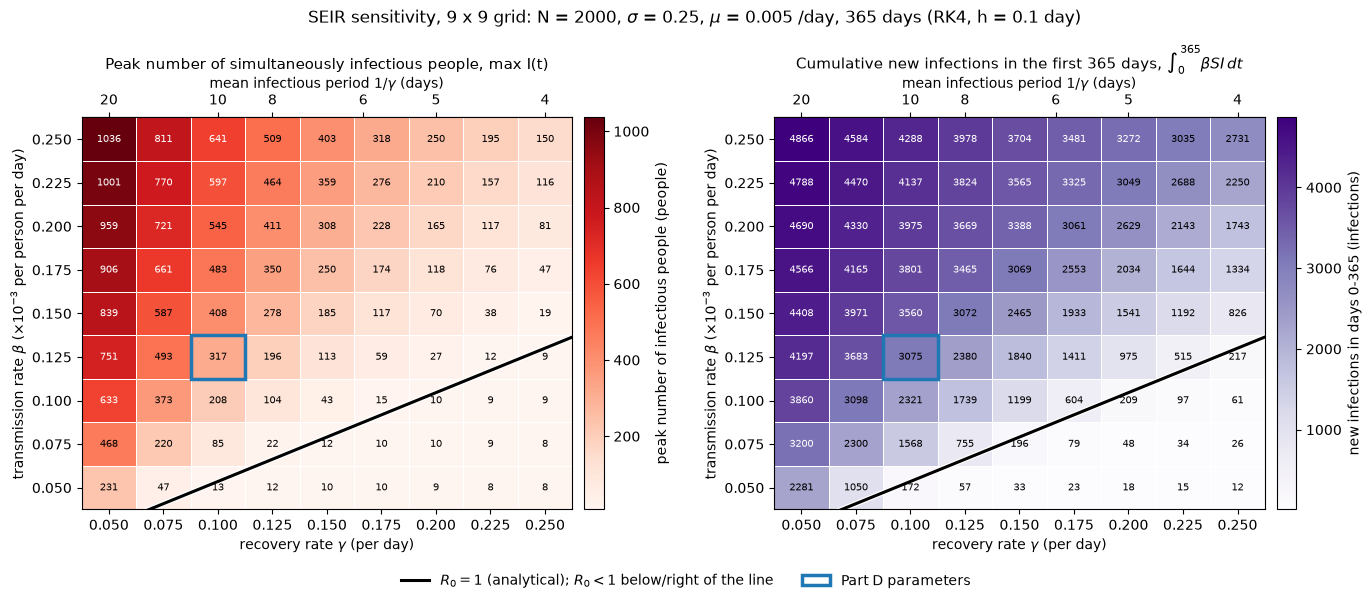

In [7]:
g_cross = betas[0] * N * sigma / (sigma + mu) - mu      # gamma where R0 = 1 on the bottom edge beta = beta_min
print(f"[analytical] R0 = 1 line: enters at beta = {betas[0]*1e3:.3f}e-3, gamma = {g_cross:.4f};  "
      f"at gamma = {gammas[-1]}: beta = {beta_on_R0_1(gammas[-1])*1e3:.4f}e-3")
print(f"[analytical] R0 on the grid: min {R0_grid.min():.3f} (beta = 0.05e-3, gamma = 0.25), "
      f"max {R0_grid.max():.3f} (beta = 0.25e-3, gamma = 0.05);  cells with R0 < 1: {(R0_grid < 1).sum()} of {R0_grid.size}")

def cell_edges(v):
    d = v[1] - v[0]
    return np.append(v - d / 2, v[-1] + d / 2)

def add_R0_line(ax, gx, label=True):
    g_line = np.linspace(gx[0], gx[-1], 400)
    ax.plot(g_line, beta_on_R0_1(g_line) * 1e3, color="k", lw=2.2, path_effects=HALO,
            label=r"$R_0 = 1$ (analytical); $R_0 < 1$ below/right of the line" if label else None)

def inverse(x):                         # 1/x, used to convert gamma <-> infectious period 1/gamma
    with np.errstate(divide="ignore"):
        return 1 / np.asarray(x, float)

def add_period_axis(ax):
    sec = ax.secondary_xaxis("top", functions=(inverse, inverse))
    sec.set_xticks([20, 10, 8, 6, 5, 4]); sec.set_xticklabels(["20", "10", "8", "6", "5", "4"])
    sec.set_xlabel(r"mean infectious period $1/\gamma$ (days)")

gx, gy = cell_edges(gammas), cell_edges(betas * 1e3)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
panels = [(peak_I,  "Reds",    "peak number of infectious people (people)",
           "Peak number of simultaneously infectious people, max I(t)"),
          (cum_inf, "Purples", "new infections in days 0-365 (infections)",
           r"Cumulative new infections in the first 365 days, $\int_0^{365}\beta SI\,dt$")]
for ax, (Z, cmap, cbar_label, title) in zip(axes, panels):
    m = ax.pcolormesh(gx, gy, Z, cmap=cmap, shading="flat", edgecolors="white", linewidth=0.5)
    fig.colorbar(m, ax=ax, pad=0.02).set_label(cbar_label)
    for i in range(n_grid):
        for j in range(n_grid):
            r_, g_, b_, _ = m.cmap(m.norm(Z[i, j]))
            dark = 0.299 * r_ + 0.587 * g_ + 0.114 * b_ < 0.5
            ax.text(gammas[j], betas[i] * 1e3, f"{Z[i, j]:.0f}", ha="center", va="center", fontsize=7.5,
                    color="white" if dark else "black")
    add_R0_line(ax, gx)
    d_g, d_b = gammas[1] - gammas[0], (betas[1] - betas[0]) * 1e3
    ax.add_patch(Rectangle((gamma0 - d_g / 2, beta0 * 1e3 - d_b / 2), d_g, d_b, fill=False,
                           ec="tab:blue", lw=2.5, label="Part D parameters"))
    ax.set_xlim(gx[0], gx[-1]); ax.set_ylim(gy[0], gy[-1])
    ax.set_xticks(gammas); ax.set_yticks(betas * 1e3)
    ax.set_xlabel(r"recovery rate $\gamma$ (per day)")
    ax.set_ylabel(r"transmission rate $\beta$ ($\times10^{-3}$ per person per day)")
    ax.set_title(title, fontsize=11)
    add_period_axis(ax)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=10, frameon=False)
fig.suptitle(f"SEIR sensitivity, 9 x 9 grid: N = {N}, $\\sigma$ = {sigma}, $\\mu$ = {mu} /day, "
             f"365 days (RK4, h = {h} day)", fontsize=12)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig("figures/partE_heatmaps.png", dpi=150); plt.show()

### Finer grid for contour plots and derivatives

To draw smooth contours and to take derivatives, the same model is run on an **81 × 81 grid** (step 0.0025; every 10th
point is a point of the 9 × 9 grid). 6561 separate `simulate` calls would take minutes, so `run_many` advances all runs
**together**: the state is a $5\times M$ array (one column per run), and each step is the same `rk4_step(seir_rhs_counted, …)`
as above. Only the loop is shared — the runs do not interact. The check below confirms that it gives the same numbers
as the double loop.

In [8]:
def run_many(beta, gamma, h=h, t_end=T):
    # Many independent SEIR runs advanced together with the same rk4_step; beta, gamma: arrays of equal shape.
    beta, gamma = np.broadcast_arrays(np.asarray(beta, float), np.asarray(gamma, float))
    p = {**base, "beta": beta.ravel(), "gamma": gamma.ravel()}
    n_steps = int(round(t_end / h))
    assert np.isclose(n_steps * h, t_end)
    tt = np.linspace(0.0, t_end, n_steps + 1)                     # same time grid as simulate()
    y = np.repeat(np.append(y0, 0.0)[:, None], beta.size, axis=1)  # column m = state of run m
    peak, tpk = y[2].copy(), np.zeros(beta.size)
    ymin, drft, fin = y[:4].min(axis=0), np.zeros(beta.size), np.ones(beta.size, dtype=bool)
    for n in range(n_steps):
        y = rk4_step(seir_rhs_counted, tt[n], y, h, p)
        new = y[2] > peak                                         # strictly higher -> keeps the first maximum
        peak[new], tpk[new] = y[2][new], tt[n + 1]
        ymin = np.minimum(ymin, y[:4].min(axis=0))
        drft = np.maximum(drft, np.abs(y[:4].sum(axis=0) - N))
        fin &= np.isfinite(y).all(axis=0)
    out = {"peak_I": peak, "t_peak": tpk, "cum_inf": y[4], "min_val": ymin, "drift": drft, "finite": fin}
    return {k: v.reshape(beta.shape) for k, v in out.items()}

n_fine = 81
fb, fg = np.linspace(betas[0], betas[-1], n_fine), np.linspace(gammas[0], gammas[-1], n_fine)
FB, FG = np.meshgrid(fb, fg, indexing="ij")                        # rows beta, columns gamma
t_start = time.perf_counter()
fine = run_many(FB, FG)
print(f"{FB.size} simulations in {time.perf_counter() - t_start:.1f} s")
R0_fine = R0_seir(FB, FG)

# Same numbers as the 9 x 9 double loop at the shared points?
sub = (slice(None, None, 10), slice(None, None, 10))
assert np.allclose(FB[sub], betas[:, None]) and np.allclose(FG[sub], gammas[None, :])
for key, A in (("peak_I", peak_I), ("t_peak", t_peak), ("cum_inf", cum_inf)):
    diff = np.abs(fine[key][sub] - A).max()
    print(f"run_many vs simulate loop, {key:8s}: max |difference| = {diff:.1e}")
    assert diff < 1e-9
assert fine["finite"].all() and fine["min_val"].min() >= 0 and fine["drift"].max() / N < 1e-10
print(f"fine grid: all finite, min value {fine['min_val'].min():g}, max |S+E+I+R-N| = {fine['drift'].max():.1e}")

6561 simulations in 2.2 s
run_many vs simulate loop, peak_I  : max |difference| = 2.3e-13
run_many vs simulate loop, t_peak  : max |difference| = 0.0e+00
run_many vs simulate loop, cum_inf : max |difference| = 2.3e-12
fine grid: all finite, min value 0, max |S+E+I+R-N| = 1.1e-11


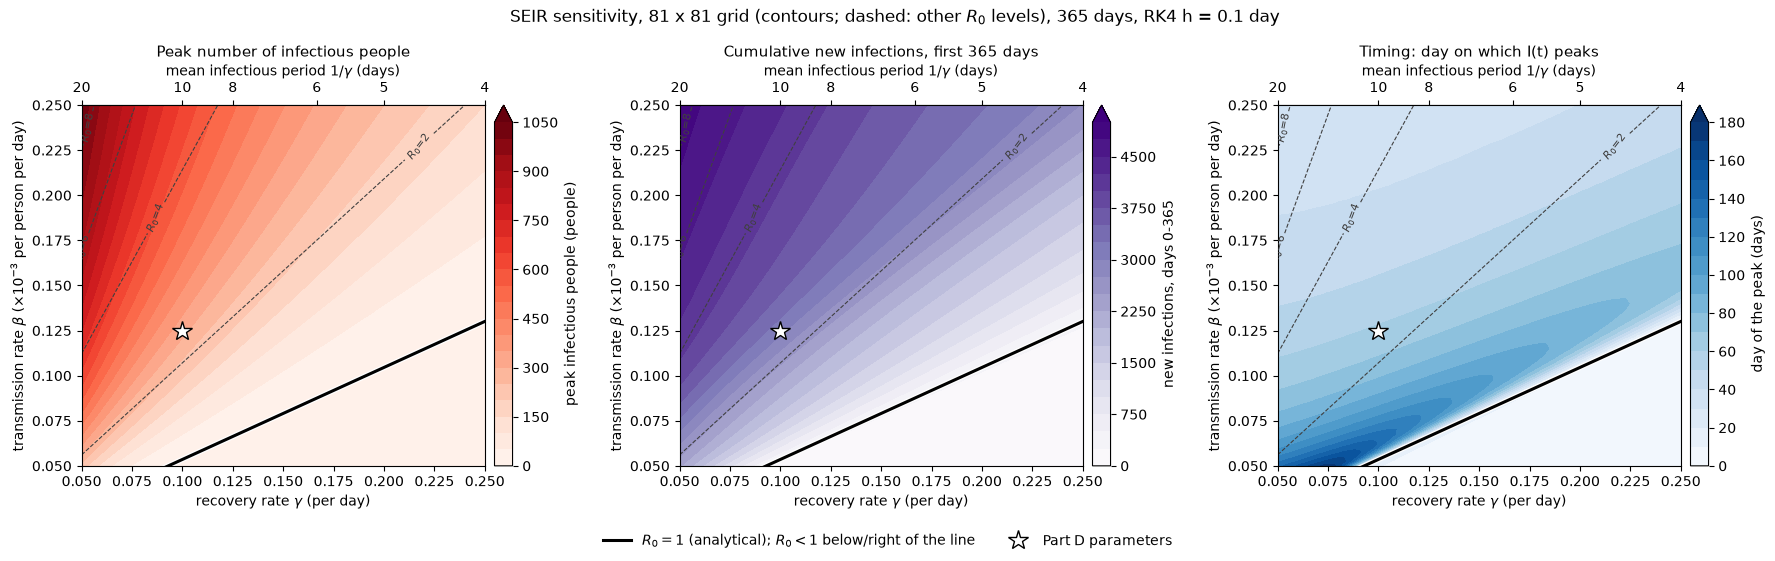

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
panels = [(fine["peak_I"],  "Reds",    np.linspace(0, 1050, 22),  "peak infectious people (people)",
           "Peak number of infectious people"),
          (fine["cum_inf"], "Purples", np.linspace(0, 5000, 21),  "new infections, days 0-365",
           "Cumulative new infections, first 365 days"),
          (fine["t_peak"],  "Blues",   np.linspace(0, 180, 19),   "day of the peak (days)",
           "Timing: day on which I(t) peaks")]
for ax, (Z, cmap, levels, cbar_label, title) in zip(axes, panels):
    cf = ax.contourf(fg, fb * 1e3, Z, levels=levels, cmap=cmap, extend="max")
    fig.colorbar(cf, ax=ax, pad=0.02).set_label(cbar_label)
    cs = ax.contour(fg, fb * 1e3, R0_fine, levels=[2, 4, 6, 8], colors="0.25", linewidths=0.8, linestyles="--")
    ax.clabel(cs, fmt=lambda v: f"$R_0$={v:.0f}", fontsize=8)
    add_R0_line(ax, fg)
    ax.plot(gamma0, beta0 * 1e3, marker="*", ms=15, mfc="white", mec="k", ls="none", label="Part D parameters")
    ax.set_xlim(fg[0], fg[-1]); ax.set_ylim(fb[0] * 1e3, fb[-1] * 1e3)
    ax.set_xlabel(r"recovery rate $\gamma$ (per day)")
    ax.set_ylabel(r"transmission rate $\beta$ ($\times10^{-3}$ per person per day)")
    ax.set_title(title, fontsize=11)
    add_period_axis(ax)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=10, frameon=False)
fig.suptitle(f"SEIR sensitivity, 81 x 81 grid (contours; dashed: other $R_0$ levels), 365 days, RK4 h = {h} day",
             fontsize=12)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig("figures/partE_contours.png", dpi=150); plt.show()

---
## Which parameter matters more?

$\beta$ (per person per day) and $\gamma$ (per day) have different units and different values, so their *absolute* changes
cannot be compared. Three unit-free comparisons are used:

1. **Equal fold changes from the Part D point.** An intervention of strength $f$ either divides the transmission rate,
   $\beta\to\beta_0/f$ (social distancing), or multiplies the recovery rate, $\gamma\to\gamma_0 f$ (treatment). Conveniently,
   $f\in[0.5,\,2.5]$ spans **exactly** both assignment ranges ($\beta_0/0.5=0.25\times10^{-3}$, $\beta_0/2.5=0.05\times10^{-3}$;
   $\gamma_0\cdot0.5=0.05$, $\gamma_0\cdot2.5=0.25$), and both ranges are a factor of 5 wide, so the ranges themselves are
   matched on a relative scale.
2. **Normalized sensitivity coefficients (elasticities)**
   $\displaystyle e_p=\frac{\partial\ln Y}{\partial\ln p}=\frac{p}{Y}\frac{\partial Y}{\partial p}$: the % change in outcome $Y$
   per 1 % change in parameter $p$. Computed at the Part D point (central differences) and over the whole fine grid.
3. **Equal percentage changes** ($\beta$ down by $x$ %, $\gamma$ up by $x$ %), the way interventions are often described.

**[analytical] Elasticities of $R_0$:** $e_\beta(R_0)=1$ and $e_\gamma(R_0)=-\gamma/(\gamma+\mu)$ (= −0.952 at $\gamma=0.1$).
So through $R_0$ alone, the two parameters are almost equally strong (β slightly stronger because of $\mu$).

In [10]:
f = np.r_[np.geomspace(0.5, 1, 31)[:-1], np.geomspace(1, 2.5, 51)]   # intervention strength (f = 1: Part D)
sw_b = run_many(beta0 / f, np.full_like(f, gamma0))   # social distancing: beta -> beta0 / f
sw_g = run_many(np.full_like(f, beta0), gamma0 * f)   # treatment:         gamma -> gamma0 * f
k1 = int(np.argmin(abs(f - 1)))
assert np.isclose(f[k1], 1) and np.isclose(sw_b["peak_I"][k1], peak_I[i0, j0])

print("[numerical] one-at-a-time sweeps from the Part D point (each parameter over its full assignment range)")
print(f"{'':28s}{'f = 0.5':>10s}{'f = 1':>10s}{'f = 2.5':>10s}{'ratio f=0.5/f=2.5':>20s}")
for name, sw in (("beta -> beta0/f   peak I", sw_b), ("gamma -> gamma0*f peak I", sw_g)):
    v = sw["peak_I"]; print(f"{name:28s}{v[0]:10.1f}{v[k1]:10.1f}{v[-1]:10.1f}{v[0] / v[-1]:20.1f}")
for name, sw in (("beta -> beta0/f   C(365)", sw_b), ("gamma -> gamma0*f C(365)", sw_g)):
    v = sw["cum_inf"]; print(f"{name:28s}{v[0]:10.0f}{v[k1]:10.0f}{v[-1]:10.0f}{v[0] / v[-1]:20.1f}")

# Local elasticities at the Part D point (central differences, two step sizes to show convergence)
def elasticities(rel):
    pts_b = run_many(beta0 * np.array([1 + rel, 1 - rel]), gamma0)
    pts_g = run_many(beta0, gamma0 * np.array([1 + rel, 1 - rel]))
    out = {}
    for key in ("peak_I", "cum_inf"):
        Y0 = rD[key]
        out[key] = [(pts[key][0] - pts[key][1]) / (2 * rel) / Y0 for pts in (pts_b, pts_g)]
    return out

print("\n[numerical] elasticities at the Part D point  (% change of the outcome per +1 % change of the parameter)")
print(f"{'outcome':24s}{'step':>7s}{'e_beta':>10s}{'e_gamma':>10s}{'|e_gamma|/|e_beta|':>21s}")
for rel in (0.01, 0.001):
    e = elasticities(rel)
    for key, lbl in (("peak_I", "peak I"), ("cum_inf", "C(365)")):
        eb, eg = e[key]
        print(f"{lbl:24s}{rel:7.1%}{eb:10.3f}{eg:10.3f}{abs(eg) / abs(eb):21.3f}")
e_loc = elasticities(0.001)
print(f"{'R0 [analytical]':24s}{'':7s}{1:10.3f}{-gamma0 / (gamma0 + mu):10.3f}{gamma0 / (gamma0 + mu):21.3f}")

[numerical] one-at-a-time sweeps from the Part D point (each parameter over its full assignment range)
                               f = 0.5     f = 1   f = 2.5   ratio f=0.5/f=2.5
beta -> beta0/f   peak I         641.4     316.9      13.3                48.4
gamma -> gamma0*f peak I         751.0     316.9       9.4                79.5
beta -> beta0/f   C(365)          4288      3075       172                25.0
gamma -> gamma0*f C(365)          4197      3075       217                19.4

[numerical] elasticities at the Part D point  (% change of the outcome per +1 % change of the parameter)
outcome                    step    e_beta   e_gamma   |e_gamma|/|e_beta|


peak I                     1.0%     1.577    -1.836                1.164
C(365)                     1.0%     1.108    -0.896                0.808


peak I                     0.1%     1.577    -1.835                1.163
C(365)                     0.1%     1.109    -0.896                0.808


R0 [analytical]                     1.000    -0.952                0.952


In [11]:
print("[numerical] equal changes applied at the Part D point")
print(f"{'change':10s}|{'beta x (1-x)':>26s} |{'beta / (1+x)':>26s} |{'gamma x (1+x)':>26s}")
print(f"{'':10s}|{'R0    peak I   C(365)':>26s} |{'R0    peak I   C(365)':>26s} |{'R0    peak I   C(365)':>26s}")
for x in (0.1, 0.2, 0.3, 0.5):
    pairs = [(beta0 * (1 - x), gamma0), (beta0 / (1 + x), gamma0), (beta0, gamma0 * (1 + x))]
    res = run_many(np.array([p[0] for p in pairs]), np.array([p[1] for p in pairs]))
    row = "".join(f"| {R0_seir(*pr):5.2f} {res['peak_I'][k]:8.1f} {res['cum_inf'][k]:8.0f}  " for k, pr in enumerate(pairs))
    print(f"{x:>8.0%}  {row}")

# Both interventions together (effects on R0 multiply, since R0 is proportional to beta / (gamma + mu))
comb = run_many(np.array([beta0 / 1.25]), np.array([gamma0 * 1.25]))
print(f"\nboth together (beta / 1.25 and gamma x 1.25): R0 = {R0_seir(beta0 / 1.25, gamma0 * 1.25):.2f}, "
      f"peak I = {comb['peak_I'][0]:.1f}, C(365) = {comb['cum_inf'][0]:.0f}")

# What is needed to push R0 below 1 from the Part D point?
R0_D = R0_seir(beta0, gamma0)
gamma_needed = (gamma0 + mu) * R0_D - mu
print(f"\n[analytical] Part D R0 = {R0_D:.3f}. R0 < 1 needs beta reduced by more than 1 - 1/R0 = {1 - 1/R0_D:.1%} "
      f"(beta < {beta0 / R0_D * 1e3:.4f}e-3),")
print(f"             or gamma raised above (gamma0+mu)*R0 - mu = {gamma_needed:.3f}/day "
      f"(x{gamma_needed / gamma0:.2f}; infectious period < {1 / gamma_needed:.1f} days)")

[numerical] equal changes applied at the Part D point
change    |              beta x (1-x) |              beta / (1+x) |             gamma x (1+x)
          |     R0    peak I   C(365) |     R0    peak I   C(365) |     R0    peak I   C(365)


     10%  |  2.10    264.6     2699  |  2.12    269.5     2735  |  2.13    262.9     2792  


     20%  |  1.87    207.5     2321  |  1.95    227.0     2442  |  1.96    216.3     2512  


     30%  |  1.63    146.6     1976  |  1.80    189.1     2213  |  1.82    176.3     2256  


     50%  |  1.17     30.6      875  |  1.56    125.8     1856  |  1.58    113.0     1840  



both together (beta / 1.25 and gamma x 1.25): R0 = 1.51, peak I = 103.8, C(365) = 1739

[analytical] Part D R0 = 2.334. R0 < 1 needs beta reduced by more than 1 - 1/R0 = 57.2% (beta < 0.0536e-3),
             or gamma raised above (gamma0+mu)*R0 - mu = 0.240/day (x2.40; infectious period < 4.2 days)


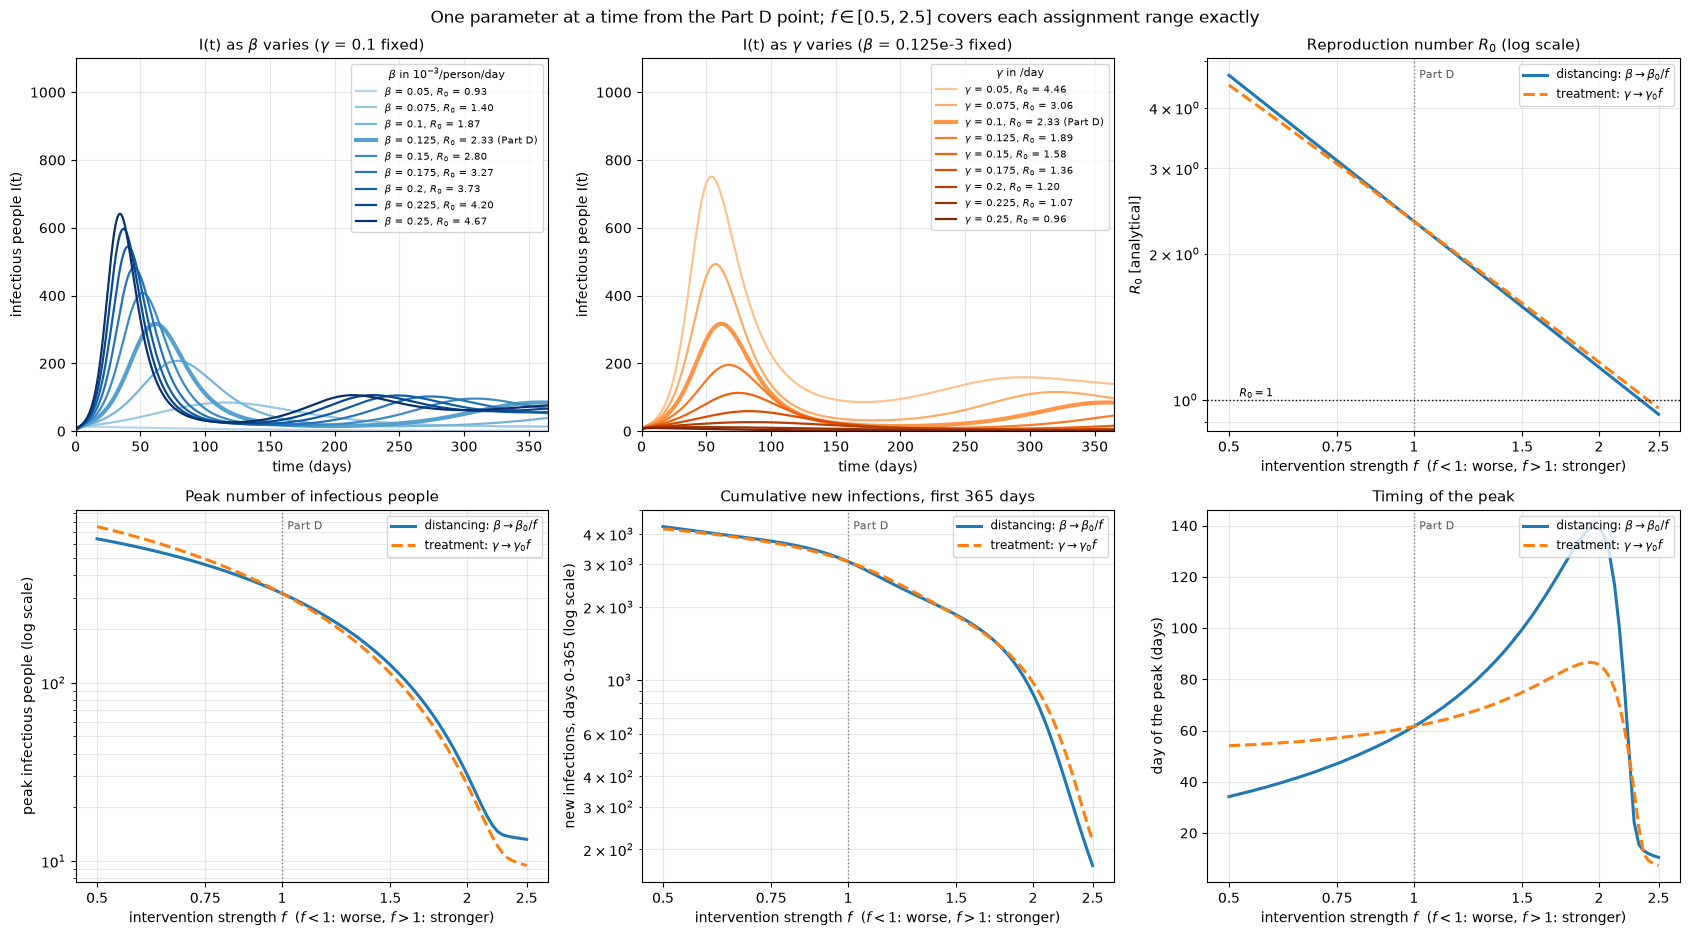

In [12]:
cmap_b, cmap_g = plt.get_cmap("Blues"), plt.get_cmap("Oranges")
fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))

# Top row: progression of the epidemic, I(t), for each parameter swept over the 9 grid values
for ax, idx, cmap, sym, other in ((axes[0, 0], [(i, j0) for i in range(n_grid)], cmap_b, r"\beta", rf"$\gamma$ = {gamma0}"),
                                  (axes[0, 1], [(i0, j) for j in range(n_grid)], cmap_g, r"\gamma",
                                   rf"$\beta$ = {beta0*1e3:.3f}e-3")):
    for n, (i, j) in enumerate(idx):
        val = betas[i] * 1e3 if sym == r"\beta" else gammas[j]
        lw = 3 if (i, j) == (i0, j0) else 1.6
        ax.plot(t, I_traj[i, j], color=cmap(0.3 + 0.7 * n / (n_grid - 1)), lw=lw,
                label=rf"${sym}$ = {val:.3g}" + (r", $R_0$ = " + f"{R0_grid[i, j]:.2f}") + (" (Part D)" if (i, j) == (i0, j0) else ""))
    ax.set_xlim(0, T); ax.set_ylim(0, 1100)
    ax.set_xlabel("time (days)"); ax.set_ylabel("infectious people I(t)")
    ax.set_title(rf"I(t) as ${sym}$ varies ({other} fixed)", fontsize=11)
    ax.legend(fontsize=7.5, loc="upper right", title=(r"$\beta$ in $10^{-3}$/person/day" if sym == r"\beta" else r"$\gamma$ in /day"),
              title_fontsize=8); ax.grid(alpha=0.3)

# Remaining panels: outcome vs intervention strength f
def sweep_panel(ax, yb, yg, ylabel, title, log=False, hline=None):
    ax.plot(f, yb, color=C_BETA, lw=2.2, label=r"distancing: $\beta\to\beta_0/f$")
    ax.plot(f, yg, color=C_GAMMA, lw=2.2, ls="--", label=r"treatment: $\gamma\to\gamma_0 f$")
    ax.axvline(1, color="0.5", lw=1, ls=":")
    ax.text(1.02, 0.97, "Part D", transform=ax.get_xaxis_transform(), fontsize=8, va="top", color="0.35")
    if hline is not None:
        ax.axhline(hline[0], color="k", lw=1, ls=":"); ax.text(0.52, hline[0], hline[1], fontsize=8, va="bottom")
    ax.set_xscale("log"); ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 2.5]); ax.set_xticklabels(["0.5", "0.75", "1", "1.5", "2", "2.5"])
    ax.minorticks_off()
    if log: ax.set_yscale("log")
    ax.set_xlabel(r"intervention strength $f$  ($f<1$: worse, $f>1$: stronger)")
    ax.set_ylabel(ylabel); ax.set_title(title, fontsize=11); ax.grid(alpha=0.3, which="both")
    ax.legend(fontsize=8.5, loc="upper right")

sweep_panel(axes[0, 2], R0_seir(beta0 / f, gamma0), R0_seir(beta0, gamma0 * f), r"$R_0$ [analytical]",
            r"Reproduction number $R_0$ (log scale)", log=True, hline=(1, r"$R_0=1$"))
sweep_panel(axes[1, 0], sw_b["peak_I"], sw_g["peak_I"], "peak infectious people (log scale)",
            "Peak number of infectious people", log=True)
sweep_panel(axes[1, 1], sw_b["cum_inf"], sw_g["cum_inf"], "new infections, days 0-365 (log scale)",
            "Cumulative new infections, first 365 days", log=True)
sweep_panel(axes[1, 2], sw_b["t_peak"], sw_g["t_peak"], "day of the peak (days)", "Timing of the peak")
fig.suptitle(r"One parameter at a time from the Part D point; $f\in[0.5,2.5]$ covers each assignment range exactly",
             fontsize=12)
plt.tight_layout(); plt.savefig("figures/partE_sweeps.png", dpi=150); plt.show()

### Elasticities over the whole grid, and is $R_0$ enough to predict the outcome?

On the 81 × 81 grid, $e_\beta=\partial\ln Y/\partial\ln\beta$ and $e_\gamma=\partial\ln Y/\partial\ln\gamma$ are computed with
`np.gradient` on $\ln Y$ against $\ln\beta$ and $\ln\gamma$. The map shows $|e_\gamma|/|e_\beta|$: **orange (> 1) = γ has the larger
effect, blue (< 1) = β has the larger effect.** The $R_0<1$ region is greyed out: no epidemic happens there, and the "peak"
only reflects the 15 initially exposed people becoming infectious (see verification 6).

The bottom panels test whether $R_0$ alone determines the outcome: if it did, all 6561 runs would fall on one curve.

[numerical] fine grid, R0 > 1 region only
  peak I: |e_gamma| > |e_beta| in 99.6% of the region;  ratio |e_gamma|/|e_beta|: median 1.19, 10-90 % range 1.06-1.39
  C(365): |e_gamma| > |e_beta| in 24.0% of the region;  ratio |e_gamma|/|e_beta|: median 0.95, 10-90 % range 0.84-1.02
  peak I, 1 < R0 < 1.5: median e_beta =  5.06, median e_gamma =  -5.38
  peak I, R0 > 5      : median e_beta =  0.48, median e_gamma =  -0.70


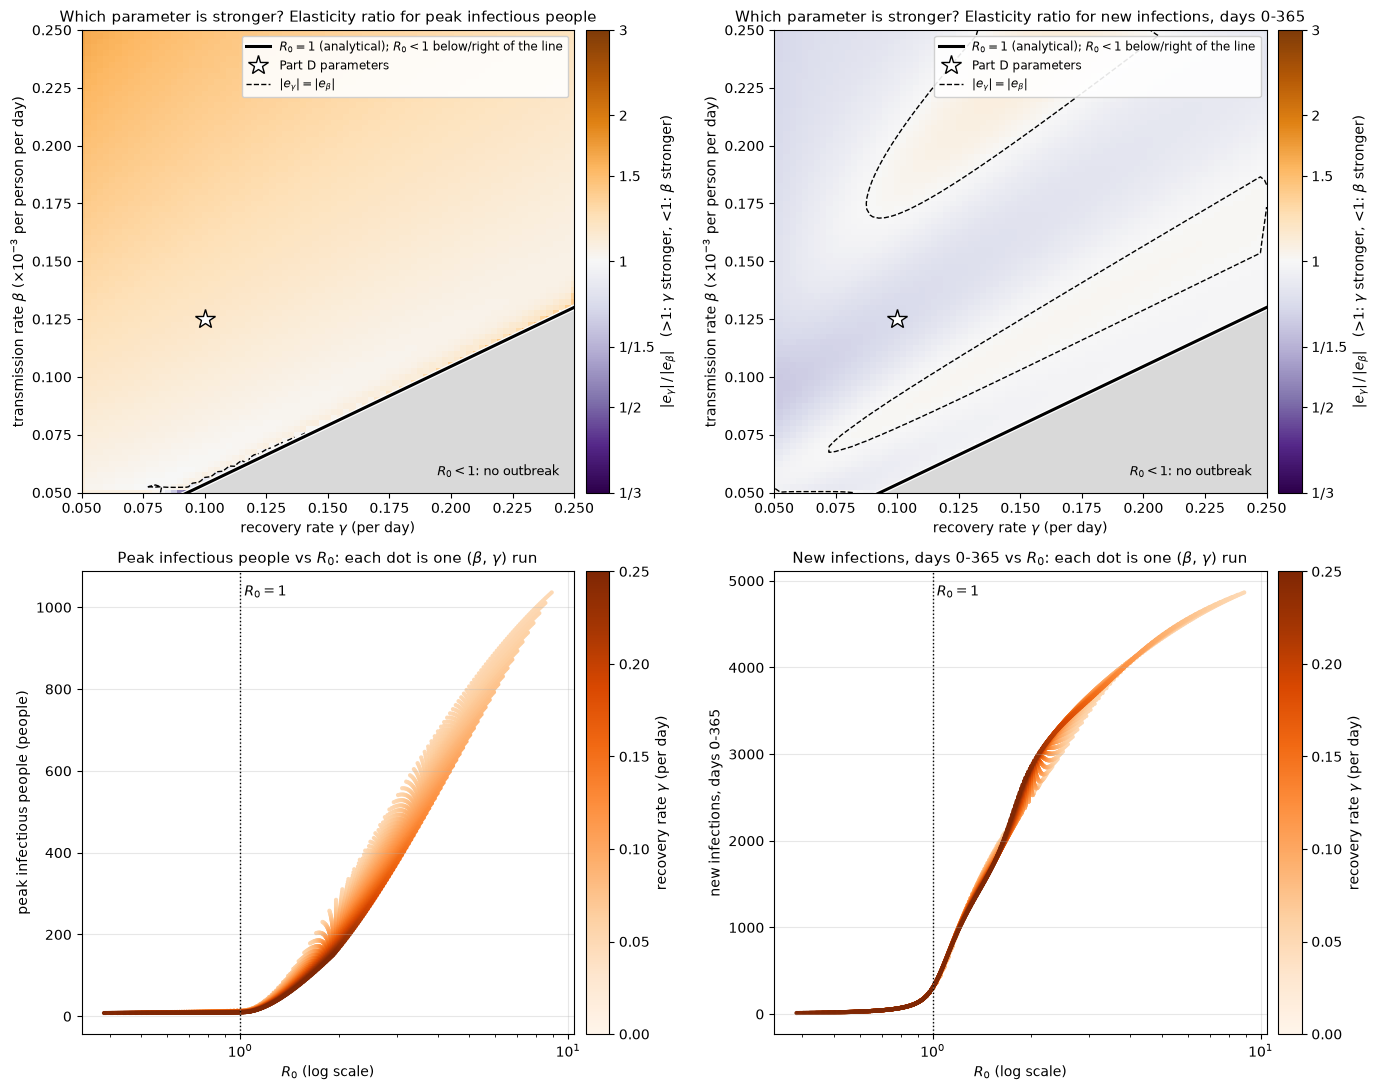

R0 within 1 % of 1.5:  75 runs, peak I from   72.4 (gamma = 0.242) to  134.8 (gamma = 0.060);  C(365) from 1628 to 1823
R0 within 1 % of 2.334:  79 runs, peak I from  234.1 (gamma = 0.205) to  382.8 (gamma = 0.050);  C(365) from 2857 to 3248
R0 within 1 % of 4.0:  44 runs, peak I from  541.0 (gamma = 0.118) to  696.6 (gamma = 0.050);  C(365) from 4054 to 4088


In [13]:
lnb, lng = np.log(fb), np.log(fg)
elas = {}
for key in ("peak_I", "cum_inf"):
    lnY = np.log(fine[key])
    elas[key] = (np.gradient(lnY, lnb, axis=0), np.gradient(lnY, lng, axis=1))     # (e_beta, e_gamma)
outbreak = R0_fine > 1

print("[numerical] fine grid, R0 > 1 region only")
for key, lbl in (("peak_I", "peak I"), ("cum_inf", "C(365)")):
    eb, eg = elas[key]
    ratio = np.abs(eg[outbreak]) / np.abs(eb[outbreak])
    print(f"  {lbl}: |e_gamma| > |e_beta| in {np.mean(ratio > 1):.1%} of the region;  ratio |e_gamma|/|e_beta|: "
          f"median {np.median(ratio):.2f}, 10-90 % range {np.quantile(ratio, 0.1):.2f}-{np.quantile(ratio, 0.9):.2f}")
eb, eg = elas["peak_I"]
for lbl, mask in (("1 < R0 < 1.5", outbreak & (R0_fine < 1.5)), ("R0 > 5", R0_fine > 5)):
    print(f"  peak I, {lbl:12s}: median e_beta = {np.median(eb[mask]):5.2f}, median e_gamma = {np.median(eg[mask]):6.2f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
norm = TwoSlopeNorm(vmin=-np.log10(3), vcenter=0, vmax=np.log10(3))
for ax, key, title in ((axes[0, 0], "peak_I", "peak infectious people"), (axes[0, 1], "cum_inf", "new infections, days 0-365")):
    eb, eg = elas[key]
    L = np.where(outbreak, np.log10(np.abs(eg) / np.abs(eb)), np.nan)
    cf = ax.pcolormesh(fg, fb * 1e3, L, cmap="PuOr_r", norm=norm, shading="nearest")
    ax.contourf(fg, fb * 1e3, (~outbreak).astype(float), levels=[0.5, 1.5], colors="0.85")
    cs = ax.contour(fg, fb * 1e3, L, levels=[0], colors="k", linewidths=1, linestyles="--")
    cb = fig.colorbar(cf, ax=ax, pad=0.02, ticks=np.log10([1/3, 1/2, 1/1.5, 1, 1.5, 2, 3]))
    cb.ax.set_yticklabels(["1/3", "1/2", "1/1.5", "1", "1.5", "2", "3"])
    cb.set_label(r"$|e_\gamma|\,/\,|e_\beta|$   (>1: $\gamma$ stronger, <1: $\beta$ stronger)")
    add_R0_line(ax, fg)
    ax.plot(gamma0, beta0 * 1e3, marker="*", ms=15, mfc="white", mec="k", ls="none", label="Part D parameters")
    ax.plot([], [], color="k", lw=1, ls="--", label=r"$|e_\gamma| = |e_\beta|$")
    ax.text(0.97, 0.03, r"$R_0<1$: no outbreak", transform=ax.transAxes, ha="right", va="bottom", fontsize=9)
    ax.set_xlim(fg[0], fg[-1]); ax.set_ylim(fb[0] * 1e3, fb[-1] * 1e3)
    ax.set_xlabel(r"recovery rate $\gamma$ (per day)")
    ax.set_ylabel(r"transmission rate $\beta$ ($\times10^{-3}$ per person per day)")
    ax.set_title(f"Which parameter is stronger? Elasticity ratio for {title}", fontsize=11)
    ax.legend(loc="upper right", fontsize=8.5, framealpha=0.9)

for ax, key, ylabel in ((axes[1, 0], "peak_I", "peak infectious people (people)"),
                        (axes[1, 1], "cum_inf", "new infections, days 0-365")):
    sc = ax.scatter(R0_fine.ravel(), fine[key].ravel(), c=FG.ravel(), cmap="Oranges", s=4, vmin=0, vmax=0.25)
    fig.colorbar(sc, ax=ax, pad=0.02).set_label(r"recovery rate $\gamma$ (per day)")
    ax.axvline(1, color="k", lw=1, ls=":"); ax.text(1.03, 0.97, r"$R_0=1$", transform=ax.get_xaxis_transform(), va="top")
    ax.set_xscale("log"); ax.set_xlabel(r"$R_0$ (log scale)"); ax.set_ylabel(ylabel); ax.grid(alpha=0.3)
    ax.set_title(f"{ylabel.split(' (')[0].capitalize()} vs $R_0$: each dot is one ($\\beta$, $\\gamma$) run", fontsize=11)
plt.tight_layout(); plt.savefig("figures/partE_elasticity.png", dpi=150); plt.show()

# How much does the peak vary among runs with (almost) the same R0?
for R0_target in (1.5, 2.334, 4.0):
    sel = np.abs(R0_fine / R0_target - 1) < 0.01
    pk, gm = fine["peak_I"][sel], FG[sel]
    print(f"R0 within 1 % of {R0_target}: {sel.sum():3d} runs, peak I from {pk.min():6.1f} (gamma = {gm[np.argmin(pk)]:.3f}) "
          f"to {pk.max():6.1f} (gamma = {gm[np.argmax(pk)]:.3f});  C(365) from {fine['cum_inf'][sel].min():.0f} "
          f"to {fine['cum_inf'][sel].max():.0f}")

---
## Verification 2: step size, independent solver, and the $R_0=1$ line

In [14]:
# 5. Smaller step sizes: the whole 9 x 9 grid again with h = 0.05 and h = 0.025
print("5. step-size check on the full 9 x 9 grid (differences relative to h = 0.1)")
for hh in (0.05, 0.025):
    g2 = run_many(betas[:, None] * np.ones((1, n_grid)), np.ones((n_grid, 1)) * gammas[None, :], h=hh)
    dP, dC, dT = (np.abs(g2[k] - A).max() for k, A in (("peak_I", peak_I), ("cum_inf", cum_inf), ("t_peak", t_peak)))
    rP, rC = (np.abs(g2[k] / A - 1).max() for k, A in (("peak_I", peak_I), ("cum_inf", cum_inf)))
    print(f"   h = {hh:5.3f}: max |d peak I| = {dP:.1e} people (rel. {rP:.1e}), max |d C(365)| = {dC:.1e} (rel. {rC:.1e}), "
          f"max |d peak day| = {dT:.2f} days")
    assert rP < 1e-4 and rC < 1e-6 and dT <= h + 1e-9

# The peak-I difference is the same for h = 0.05 and 0.025, so it is NOT integration error (that would shrink ~16x
# per halving): a finer time grid simply samples I(t) closer to its true maximum. Comparing whole trajectories at the
# common times isolates the integration error:
i, j = np.unravel_index(np.argmax(np.abs(g2["peak_I"] - peak_I)), peak_I.shape)
p = {**base, "beta": betas[i], "gamma": gammas[j]}
_, Y_fine = simulate(seir_rhs_counted, np.append(y0, 0.0), T, 0.025, p)
traj_err = np.abs(Y_fine[::4, 2] - I_traj[i, j]).max()
print(f"   worst cell (beta = {betas[i]*1e3:.3f}e-3, gamma = {gammas[j]:.3f}): max |I_h=0.1(t) - I_h=0.025(t)| at common times"
      f" = {traj_err:.1e} people -> the {np.abs(g2['peak_I'] - peak_I).max():.1e} difference is time sampling of the maximum")
assert traj_err < 1e-5

# Independent solver (verification only): SciPy DOP853 with tight tolerances at corners, Part D point, near threshold
print("\n   independent check with scipy solve_ivp (DOP853, rtol 1e-12) on the same time grid")
check_pts = [(betas[0], gammas[0]), (betas[0], gammas[-1]), (betas[-1], gammas[0]), (betas[-1], gammas[-1]),
             (beta0, gamma0), (betas[1], gammas[3])]
for b, g in check_pts:
    p = {**base, "beta": b, "gamma": g}
    sol = solve_ivp(lambda tt, y: seir_rhs_counted(tt, y, p), (0, T), np.append(y0, 0.0), method="DOP853",
                    t_eval=t, rtol=1e-12, atol=1e-10)
    i, j = int(np.argmin(abs(betas - b))), int(np.argmin(abs(gammas - g)))
    dP, dC = abs(sol.y[2].max() - peak_I[i, j]), abs(sol.y[4, -1] - cum_inf[i, j])
    print(f"   beta = {b*1e3:.3f}e-3, gamma = {g:.3f} (R0 = {R0_seir(b, g):.2f}):  |d peak I| = {dP:.1e},  |d C(365)| = {dC:.1e}")
    assert dP < 1e-4 and dC < 1e-4

5. step-size check on the full 9 x 9 grid (differences relative to h = 0.1)


   h = 0.050: max |d peak I| = 4.4e-03 people (rel. 3.4e-05), max |d C(365)| = 1.8e-07 (rel. 3.7e-11), max |d peak day| = 0.05 days


   h = 0.025: max |d peak I| = 4.4e-03 people (rel. 3.4e-05), max |d C(365)| = 1.9e-07 (rel. 4.0e-11), max |d peak day| = 0.05 days


   worst cell (beta = 0.250e-3, gamma = 0.100): max |I_h=0.1(t) - I_h=0.025(t)| at common times = 2.7e-07 people -> the 4.4e-03 difference is time sampling of the maximum

   independent check with scipy solve_ivp (DOP853, rtol 1e-12) on the same time grid
   beta = 0.050e-3, gamma = 0.050 (R0 = 1.78):  |d peak I| = 1.5e-10,  |d C(365)| = 7.9e-11
   beta = 0.050e-3, gamma = 0.250 (R0 = 0.38):  |d peak I| = 8.2e-08,  |d C(365)| = 5.1e-11
   beta = 0.250e-3, gamma = 0.050 (R0 = 8.91):  |d peak I| = 3.5e-07,  |d C(365)| = 1.9e-07


   beta = 0.250e-3, gamma = 0.250 (R0 = 1.92):  |d peak I| = 1.1e-08,  |d C(365)| = 6.5e-09
   beta = 0.125e-3, gamma = 0.100 (R0 = 2.33):  |d peak I| = 8.7e-09,  |d C(365)| = 5.7e-09
   beta = 0.075e-3, gamma = 0.125 (R0 = 1.13):  |d peak I| = 1.6e-10,  |d C(365)| = 6.8e-10


In [15]:
# 6. The R0 = 1 line
gg = np.linspace(0.0, 0.3, 301)
err = np.abs(R0_seir(beta_on_R0_1(gg), gg) - 1).max()
print(f"6a. [analytical] R0(beta*(gamma), gamma) - 1 on 301 gamma values: max |error| = {err:.1e}")
assert err < 1e-12

# (b) Independent derivation: linear stability of the disease-free state (S = N, E = I = R = 0).
#     The infection can grow only if the Jacobian there has an eigenvalue with positive real part.
def jacobian_dfe(b, g):
    return np.array([[-mu, 0,            -b * N,        0],
                     [0,   -(sigma + mu), b * N,        0],
                     [0,    sigma,       -(g + mu),     0],
                     [0,    0,            g,          -mu]])
lead = lambda b, g: np.linalg.eigvals(jacobian_dfe(b, g)).real.max()
on   = max(abs(lead(beta_on_R0_1(g), g)) for g in gammas)
above = min(lead(1.01 * beta_on_R0_1(g), g) for g in gammas)
below = max(lead(0.99 * beta_on_R0_1(g), g) for g in gammas)
print(f"6b. leading eigenvalue at the disease-free state:  on the line max |lambda| = {on:.1e};  "
      f"1 % above: min {above:+.2e} (> 0, grows);  1 % below: max {below:+.2e} (< 0, dies out)")
assert on < 1e-12 and above > 0 and below < 0

# (c) Consistency with the simulations
lo, hi = R0_grid < 1, R0_grid > 1
print(f"6c. R0 < 1 cells ({lo.sum()}): peak I <= {peak_I[lo].max():.1f} people, reached by day {t_peak[lo].max():.1f}, "
      f"C(365) <= {cum_inf[lo].max():.0f};  I(365) <= {I_traj[lo][:, -1].max():.2f}")
print(f"    R0 > 1 cells ({hi.sum()}): peak reached on day {t_peak[hi].min():.1f} or later;  "
      f"lowest peak {peak_I[hi].min():.1f} at R0 = {R0_grid[hi][np.argmin(peak_I[hi])]:.3f}")
I_up_from = y0[2]
print(f"    (in R0 < 1 cells I first rises above I(0) = {I_up_from:.0f}: the 15 exposed people become infectious, "
      f"sigma*E(0) = {sigma*y0[1]:.2f} > (gamma+mu)*I(0) for every gamma in the grid)")
assert t_peak[lo].max() < t_peak[hi].min()

6a. [analytical] R0(beta*(gamma), gamma) - 1 on 301 gamma values: max |error| = 2.2e-16
6b. leading eigenvalue at the disease-free state:  on the line max |lambda| = 0.0e+00;  1 % above: min +4.52e-04 (> 0, grows);  1 % below: max -4.53e-04 (< 0, dies out)
6c. R0 < 1 cells (16): peak I <= 13.3 people, reached by day 10.5, C(365) <= 217;  I(365) <= 0.87
    R0 > 1 cells (65): peak reached on day 33.3 or later;  lowest peak 11.9 at R0 = 1.066
    (in R0 < 1 cells I first rises above I(0) = 5: the 15 exposed people become infectious, sigma*E(0) = 3.75 > (gamma+mu)*I(0) for every gamma in the grid)


---
## E(iii) Results and discussion

All numbers below are printed by the cells above.

**Range of outcomes (9 × 9 grid, first 365 days).**
* **Peak infectious:** from **8.0** people ($\beta=0.05\times10^{-3}$, $\gamma=0.25$, $R_0=0.38$) to **1036** people
  ($\beta=0.25\times10^{-3}$, $\gamma=0.05$, $R_0=8.9$), i.e. **52 %** of the population infectious at the same time.
  Part D: 316.9 on day 61.6.
* **New infections in 365 days:** from **12** to **4866** infections (Part D: 3075). Values above $N=2000$ are possible
  because 3650 people are born during the year (see the counting note above).
* **Peak timing:** from day 3.2 (no outbreak) to day 173.8 ($R_0=1.23$); every peak is inside the window.

**How β and γ change the epidemic.**
* **Both act mainly through $R_0\propto\beta/(\gamma+\mu)$.** Raising β or lowering γ gives a higher, earlier peak and
  more infections. The contour lines of both outcomes run almost parallel to the $R_0$ lines (contour figure).
  Measured as elasticities, $R_0$ is almost equally sensitive to both: $e_\beta=1$, $e_\gamma=-0.95$.
* **Peak infections: γ has the stronger effect.** At the Part D point, a 1 % change changes the peak by **+1.58 %** (β)
  vs **−1.84 %** (γ). Over the full ranges from the Part D point, which are equal fold-changes (×0.5 to ×2.5):
  * the β sweep moves the peak from 641 to 13 (**×48**);
  * the γ sweep moves it from 751 to 9 (**×80**).

  The same holds over 99.6 % of the $R_0>1$ region (median $|e_\gamma|/|e_\beta|=1.19$). **Reason:** γ plays **two
  roles**. Like β, it sets $R_0$ (number of new infections per case). But $I$ is a *prevalence*: the rate at which
  people become infectious **times how long they stay infectious**, $1/(\gamma+\mu)$. A shorter infectious period lowers the
  number of people infectious at once even at the *same* $R_0$. At $R_0\approx2.33$, the peak ranges from 383
  ($\gamma=0.05$) to 234 ($\gamma=0.205$) (bottom-left scatter). β has no second role of this kind.
* **Cumulative infections: β is slightly stronger.** Elasticities **+1.11** (β) vs **−0.90** (γ) at Part D. The full-range
  effect is ×25 vs ×19, and β is stronger in 76 % of the $R_0>1$ region (median ratio 0.95). Cumulative infections are
  almost a function of $R_0$ alone (the scatter collapses onto one curve), and $R_0$ is slightly more sensitive to β.
  Remaining spread: at equal $R_0$, faster epidemics (large β *and* γ) complete more of their second wave within the
  365 days.
* **Timing:** reducing β delays the peak much more than raising γ: up to day ≈ 140 vs ≈ 87 in the sweeps, before both
  collapse near $R_0=1$. A shorter infectious period also shortens the time between generations of cases, which
  partly cancels the slower growth.
* **Equal percentage changes.** Cutting β by $x$ % and raising γ by $x$ % have similar effects for $x=10$ %. For larger
  $x$, the β cut wins (30 %: peak 147 vs 176; 50 %: 31 vs 113). This is not a contradiction: a 50 % cut halves β
  (×2), whereas +50 % multiplies γ by only 1.5. At equal **fold** changes ($\beta/(1+x)$ vs $\gamma(1+x)$), the γ
  change lowers the peak more at every $x$. Comparing equal percentages therefore favours β by construction.
  Fold changes (elasticities) are the defensible comparison.

**Nonlinear effects and behaviour near $R_0=1$.**
* **Threshold.** In the 16 cells with $R_0<1$, there is no epidemic: the "peak" (≤ 13 people, by day 10.5) is only the
  15 initially exposed people becoming infectious, $C(365)\le217$, and $I(365)<1$. The analytical line agrees with the
  linear stability of the disease-free state and with the simulations (verification 6).
* **Steepness near the threshold.** For $1<R_0<1.5$, the median elasticities of the peak are ≈ +5.1 (β) and −5.4 (γ):
  a 1 % change moves the peak by ≈ 5 %. For $R_0>5$, they fall to +0.5 and −0.7. Both outcomes **saturate** at high
  $R_0$, because there are only so many susceptibles. Partial interventions therefore mainly *delay* very
  transmissible outbreaks, but have large relative payoffs once $R_0$ is near 1.
* **Non-monotone timing.** As either intervention gets stronger, the peak first moves later ("flattening the curve").
  Just above $R_0=1$ the epidemic is slow, small and late (e.g. peak day 174 at $R_0=1.23$). Below 1, the peak suddenly
  jumps back to the initial transient (day ≈ 3–10). The dark ridge in the timing contour runs along the threshold.
* **Second waves within the year.** At high β, births refill $S$ fast enough for a second wave inside 365 days
  ($I(t)$ panels). This is why $C(365)$ keeps rising with $R_0$ beyond $N$.

**Public-health implications.**
* **β ↔ social distancing** (fewer contacts, masks, ventilation). It acts through $R_0$ and is the strongest lever for
  **total infections** and for **delaying** the peak (time to prepare treatment or vaccines). From the Part D point, $R_0<1$
  needs β reduced by more than **57 %**.
* **γ ↔ medical treatment** that shortens the **infectious** period (e.g. antivirals). In this model, anything that
  removes infectious people from transmission (testing and isolation of cases) also raises γ. Per fold-change, it is the
  stronger lever for the **peak**, which matters most for healthcare capacity. Note that $I$ counts infectious people,
  not hospital patients. Treatment that only relieves symptoms without shortening infectiousness does not change γ.
  $R_0<1$ by γ alone would need γ ×2.4 (infectious period below 4.2 days), which is hard to reach by treatment alone.
* **Combining both.** Effects multiply in $R_0$: β/1.25 together with γ ×1.25 gives $R_0=1.51$, peak 104 instead of 317, and 1739 instead of 3075 infections.
  Combined moderate measures can reach the steep region near $R_0=1$, where every extra percent pays off most.

### Hypothesis (iii) revisited: "β affects the peak more than γ"

**Mostly not supported for the peak; partly supported overall.**
* With fair, unit-free comparisons (equal fold changes, elasticities), **γ affects the peak more**:
  * by ≈ 16 % at the Part D point (1.84 vs 1.58);
  * ×80 vs ×48 over the assignment ranges;
  * in almost the whole outbreak region.

  The reason is the second role of γ described above: it also sets how long each person stays infectious.
* The intuition behind my hypothesis is right for **cumulative infections**, for **$R_0$** (slightly) and for the
  **timing** of the peak: there, β is the stronger parameter. It is also right when interventions are compared as equal
  *percentages* of 20 % or more, but that comparison is biased towards β (see above).
* Overall, the two parameters are of **similar strength** (elasticities within ≈ 20 % of each other), because both work
  mainly through $R_0$. The difference between them is a second-order effect, whose sign depends on the outcome measured.

### Limitations and unexpected behaviour

* **Peak = infectious people only** ($I$). "Infected" could also include exposed people ($E+I$), which gives larger numbers.
  The peak is the largest value on the $h=0.1$ day grid (within $4\times10^{-3}$ people of the true maximum).
* **Fixed 365-day horizon.** Near $R_0=1$, epidemics are slow and are not finished in a year. At high $R_0$, part of a
  second wave is included. $C(365)$ depends on the horizon.
* **Unrealistic turnover** ($1/\mu=200$ days, as in Part D) adds 3650 births per year. With a realistic lifespan,
  $C(365)$ could not exceed $S(0)$ by much, and recurrent waves would not appear within a year.
* **Deterministic model.** Near the threshold, peaks of ~10 people would in reality be subject to chance extinction. A
  stochastic model would be needed there.
* **Local measures.** Elasticities and one-at-a-time sweeps depend on the reference point. The full-grid maps reduce this
  concern, but σ, μ and the initial conditions were kept fixed. Grid derivatives straddling the $R_0=1$ line are noisy.
* **Unexpected:** in the $R_0<1$ cells, $I$ still rises at first (to ≈ 8–13), because $E(0)=15$. $C(365)$ exceeds $N$.
  At equal $R_0$, a faster epidemic gives slightly *more* infections within the year.

---
## Summary of numerical verification

| check | result |
|---|---|
| 1. every combination evaluated | 81 of 81 (9 × 9) and 6561 of 6561 (81 × 81); no NaN |
| 2. finite and nonnegative | all trajectories finite; smallest S, E, I, R value 0 (only $R(0)=0$); all outcomes ≥ 0 |
| 3. conservation | $\max|S+E+I+R-N|\approx6\times10^{-12}$ people over all runs |
| 4. Part D reproduced | peak day 61.6, $I$ = 316.92, $C(365)$ = 3075.25 (Part D: 2181.8 + 893.5 = 3075.3); trajectory bit-identical |
| cumulative infections | RK4 counter = trapezoid rule = susceptible balance (3075.246); $N-S(365)=1170$ shown to be wrong |
| 5. smaller step | $h=0.05, 0.025$: $C(365)$ changes by < $10^{-6}$; peak differences ($4\times10^{-3}$ people) are time sampling, trajectories agree to < $10^{-5}$ |
| independent solver | SciPy DOP853 agrees to < $10^{-6}$ people at 6 points (corners, Part D, near threshold) |
| vectorised runs | `run_many` = `simulate` loop to $10^{-12}$ |
| 6. $R_0=1$ line | substitution gives $R_0=1$ to $10^{-16}$; disease-free state changes stability exactly on the line; $R_0<1$ cells show no outbreak |